# EVE with behavioural assumptions: non-maturity deposits, deposit betas and prepayment

**Question:** how much of the EVE risk of the bank that failed in 2023 depends on what is assumed about its deposits, what do the standard's caps, a replicating portfolio, a deposit beta and prepayment do to that assumption, and does the behavioural layer move the EVE measure across the 15 percent outlier line?

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 01 and 02 of this topic
- **Reading time:** about 55 minutes

## Objectives

By the end of this notebook you can:

- split a non-maturity deposit into a non-core and a core part with the caps of the standardised framework, and say what changes when the caps are removed;
- explain the replicating portfolio of a deposit, read its weights and its weighted average maturity, and say why those weights are unstable;
- apply a deposit beta with different pass-through up and down, and the prepayment and early-redemption conversions (SMM, CPR, PSA and the multipliers by shock);
- compute the EVE risk measure with and without the behavioural layer, read the outlier test, and say why the engine tests the two together.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.irrbb import behavioural, eve_nii, shocks, slotting
from riskvalidation.validation import irrbb as rv_irrbb

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2


## Data

The data is case C14, the interest rate risk in the banking book (IRRBB) of the bank that failed in March 2023, at three valuation dates, 2021-Q4, 2022-Q2 and 2022-Q4, as Contraste commits it. The FDIC call reports (FDIC BankFind financials, https://api.fdic.gov/banks/financials) and the US Treasury par curve (https://home.treasury.gov/resource-center/data-chart-center/interest-rates) are public-domain sources of the licence class `mirror-allowed`. The bank is **real in aggregate and synthetic in behaviour**: the call report holds no deposit behaviour, so the share and the maturity of the stable deposits, the prepayment and the early redemption are stated by Contraste and labelled synthetic; the deposit betas and the replicating-portfolio weights are fitted on the report history up to each date and never read later data. Money is in USD thousands and a positive delta EVE is a loss.

- **Files read:** `data/derived/C14/vd-2021-q4.json`, `vd-2022-q2.json` and `vd-2022-q4.json` (`outputs.nmd_segments`, `behavioural_comparison`, `scenarios`; `tests`; `impact`) and `data/derived/C14/models-svb-2021-2022.json` (`fit.nmd_models`, `multipliers`).

The next cell loads the four files and lists the three segments of non-maturity deposits.

In [2]:
# Load the three valuation dates and the model document (the notebook sits three folders below the repository root)
ROOT = Path("../../..").resolve()
derived = ROOT / "data" / "derived" / "C14"
quarters = ("2021-Q4", "2022-Q2", "2022-Q4")
docs = {q: json.loads((derived / f"vd-{q.lower()}.json").read_text(encoding="utf-8")) for q in quarters}
fit = json.loads((derived / "models-svb-2021-2022.json").read_text(encoding="utf-8"))["fit"]
out = docs["2022-Q2"]["outputs"]
MID = slotting.bucket_grid().midpoints
r0 = np.array(out["curve"]["zero_rates_at_midpoints"])
LANG = "en"  # the bilingual fields of the documents are read in this language
NAME = {"retail-transactional": "retail transactional", "retail-non-transactional": "retail non-transactional"}
NAME.update({"wholesale": "wholesale"})
NAME.update({"behavioural": "behavioural", "contractual": "contractual", True: "yes", False: "no"})
NAME.update({"parallel-up": "parallel up", "parallel-down": "parallel down", "steepener": "steepener"})
NAME.update({"flattener": "flattener", "short-up": "short up", "short-down": "short down"})
print("segments of non-maturity deposits at 2022-Q2:", [NAME[s["category"]] for s in out["nmd_segments"]])

segments of non-maturity deposits at 2022-Q2: ['retail transactional', 'retail non-transactional', 'wholesale']


## Method

The method has five steps: (1) the split of a non-maturity deposit, (2) the replicating portfolio, (3) the deposit beta, (4) prepayment and early redemption, (5) the EVE with and without the behavioural layer.

### Step 1: the split of a non-maturity deposit with the standard's caps

A non-maturity deposit (NMD) has no contractual maturity, but part of it is stable. The standardised framework slots the **non-core** part, $(1 - s)\,B$ of a balance $B$ with core share $s$, in the overnight band, and the **core** part, $s\,B$, in the two bands whose midpoints bracket the average maturity $m$ of the core, with weights chosen so that the weighted average maturity of the core is exactly $m$. The share and the maturity are capped by category (BCBS, SRP31.107 to SRP31.112, Table 4, https://www.bis.org/basel_framework/chapter/SRP/31.htm): retail transactional at most 90 percent and 5 years, retail non-transactional 70 percent and 4.5 years, wholesale 50 percent and 4 years:

$$s_{used} = \min(s_{request},\ s_{cap}), \qquad m_{used} = \min(m_{request},\ m_{cap})$$

The engine's `nmd_split` returns the 19-band flows, the request, the cap and the used value of both, and whether a cap bit. The product asks for values above every cap on purpose (synthetic requests of 95, 75 and 60 percent), so the standardised treatment cuts them and says so. The next cell splits the three segments of the 2022-Q2 balance sheet, and draws the flows by band.

retail transactional: balance 2,723,410
    request 0.95/6.0 | cap 0.90/5.0 | used 0.90/5.0 | cap applied: yes
    average maturity of the core (y): 5.0000
retail non-transactional: balance 1,726,590
    request 0.75/5.0 | cap 0.70/4.5 | used 0.70/4.5 | cap applied: yes
    average maturity of the core (y): 4.5000
wholesale: balance 185,381,000
    request 0.60/5.0 | cap 0.50/4.0 | used 0.50/4.0 | cap applied: yes
    average maturity of the core (y): 4.0000


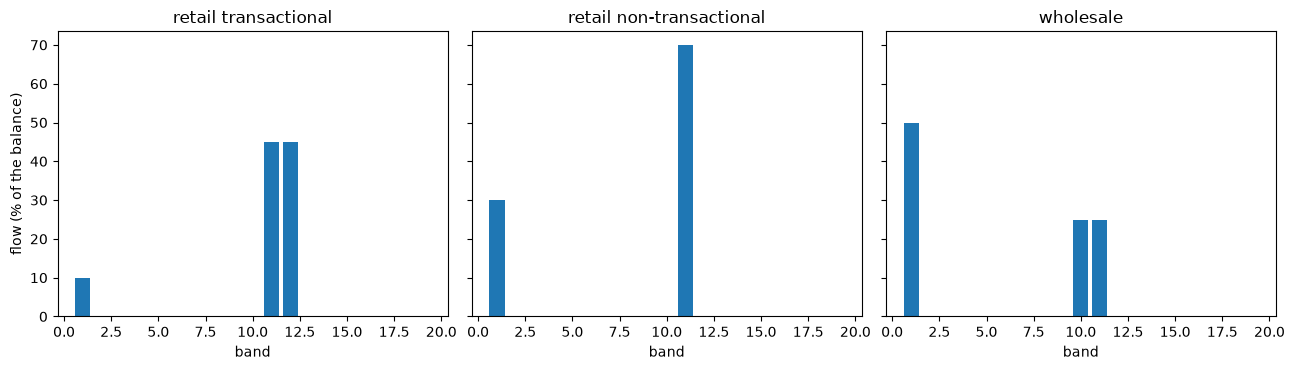

In [3]:
# Split each segment of the 2022-Q2 balance sheet with the standard's caps and draw the flows by band
splits = {}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, seg in zip(axes, out["nmd_segments"]):
    args = (seg["balance"], seg["category"], seg["requested_core_share"], seg["requested_core_maturity_years"])
    r = slotting.nmd_split(*args)
    splits[seg["category"]] = r
    asked = f"{r.requested_core_share:.2f}/{r.requested_core_maturity_years:.1f}"
    cap = f"{r.core_share_cap:.2f}/{r.core_maturity_cap_years:.1f}"
    used = f"{r.core_share_used:.2f}/{r.core_maturity_used_years:.1f}"
    wam = (r.flows[1:] * MID[1:]).sum() / r.flows[1:].sum()
    print(f"{NAME[seg['category']]}: balance {seg['balance']:,.0f}")
    print(f"    request {asked} | cap {cap} | used {used} | cap applied: {NAME[r.cap_applied]}")
    print(f"    average maturity of the core (y): {wam:.4f}")
    ax.bar(np.arange(1, 20), r.flows / seg["balance"] * 100)
    ax.set_title(NAME[seg["category"]])
    ax.set_xlabel("band")
axes[0].set_ylabel("flow (% of the balance)")
fig.tight_layout()
plt.show()

The three panels show the same rule on three balances. The non-core part, 10, 30 or 50 percent of the balance depending on the cap, sits in the first bar, overnight; the core part sits in the bars of the two bands that bracket its maturity, 5 years for the retail transactional segment, 4.5 for the non-transactional one and 4 for the wholesale one, and the printed average maturity of the core part is exactly the maturity used. The requests of the product (95, 75 and 60 percent) were above every cap, so every cap bit. The picture shows shares of the balance, not money: the wholesale segment is 185 billion dollars against under 3 billion for the two retail ones, so the wholesale bar decides the result.

What the caps are worth. The next cell takes the wholesale segment, by far the largest, and computes the present value of its flows with the caps and with the request as stated (`enforce_caps=False`), using the zero curve of the date. The request is longer and more stable than the standard allows, so the deposits look longer-lived, their present value as a liability is lower, and the EVE of the bank is higher: the caps stop the assumption from making the bank look safer than the standard allows.

cap applied: with caps yes | without caps no
present value of the liability with the caps      174,964,140
present value of the liability as requested      169,928,511
EVE raised by not applying the caps        5,035,629


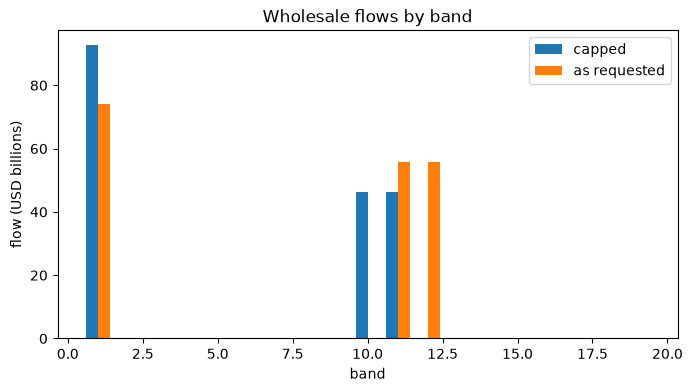

In [4]:
# The wholesale deposits with the caps and with the request as stated: present value and flows by band
seg = next(s for s in out["nmd_segments"] if s["category"] == "wholesale")
args = (seg["balance"], "wholesale", seg["requested_core_share"], seg["requested_core_maturity_years"])
capped = slotting.nmd_split(*args)
asked = slotting.nmd_split(*args, enforce_caps=False)
pv_capped = eve_nii.eve(capped.flows, r0, MID)
pv_asked = eve_nii.eve(asked.flows, r0, MID)
print("cap applied: with caps", NAME[capped.cap_applied], "| without caps", NAME[asked.cap_applied])
print(f"present value of the liability with the caps {pv_capped:16,.0f}")
print(f"present value of the liability as requested {pv_asked:16,.0f}")
print(f"EVE raised by not applying the caps {pv_capped - pv_asked:16,.0f}")
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(np.arange(1, 20) - 0.2, capped.flows / 1e6, 0.4, label="capped")
ax.bar(np.arange(1, 20) + 0.2, asked.flows / 1e6, 0.4, label="as requested")
ax.set_xlabel("band")
ax.set_ylabel("flow (USD billions)")
ax.set_title("Wholesale flows by band")
ax.legend()
plt.show()

The request as stated puts 60 percent of the wholesale balance in the core and spreads it around 5 years, so its bars are lower overnight and higher in the long bands than the capped ones. A liability that sits further out is worth less today, which is why the present value falls from the capped figure to the requested one and the EVE rises by the difference printed above. The caps therefore stop an assumption from making the bank look safer than the standard allows. What the figure does not show is how large this is against the bank: that comparison with Tier 1 comes in the Results.

### Step 2: the replicating portfolio

The standard caps the deposit's assumptions; a bank's own model has to choose them. The most common internal model is the **static replicating portfolio**: choose weights $w_j \ge 0$ summing to one on rolling tranches of maturities $m_j$ so that the margin $\mu_t = \sum_j w_j\, y_{jt} - i_t$, the replicating yield minus the client rate $i_t$, has the smallest possible variance. A rolling tranche of maturity $m$ reinvested evenly over its life has a weighted average maturity of $m/2$, so the implied maturity of the deposit is

$$WAM = \frac{1}{2} \sum_j w_j\, m_j$$

(BCBS d368, footnote 38, https://www.bis.org/bcbs/publ/d368.htm, as read in dossier 05, D.3; the dynamic version is Kalkbrener and Willing, 2004, https://doi.org/10.1016/S0378-4266(03)00131-6). The engine's `replicating_portfolio` solves the constrained problem exactly up to 10 tranches, and `weighted_average_maturity` applies the formula. First, the fits of the pipeline: the weights of the wholesale model at each date, and the average maturity the engine gives for them.

2021-12-31 wholesale | {0.25: 0.0493, 10.0: 0.9507}
    average maturity (y) 4.7595 | margin volatility 0.00803
2022-06-30 wholesale | {0.25: 0.1631, 10.0: 0.8369}
    average maturity (y) 4.2049 | margin volatility 0.00768
2022-12-31 wholesale | {10.0: 1.0}
    average maturity (y) 5.0000 | margin volatility 0.00823


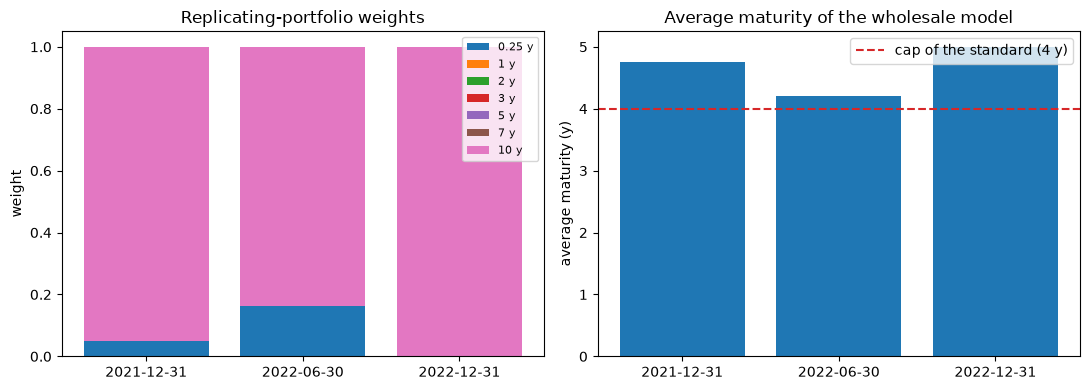

In [5]:
# The replicating-portfolio weights fitted at each date, and the average maturity the engine gives for them
models = fit["nmd_models"]
years = np.array([t["maturity_years"] for t in models[0]["tranches"]])
weights = np.array([[t["weight"] for t in m["tranches"]] for m in models])
wams = [behavioural.weighted_average_maturity(years, w) for w in weights]
for m, w, wam in zip(models, weights, wams):
    used = {float(y): round(float(x), 4) for y, x in zip(years, w) if x > 0}
    print(m["valuation_date"], NAME[m["category"]], "|", used)
    print(f"    average maturity (y) {wam:.4f} | margin volatility {m['margin_volatility']:.5f}")
dates = [m["valuation_date"] for m in models]
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
bottom = np.zeros(len(models))
for j, y in enumerate(years):
    left.bar(dates, weights[:, j], bottom=bottom, label=f"{y:g} y")
    bottom += weights[:, j]
left.set_ylabel("weight")
left.set_title("Replicating-portfolio weights")
left.legend(fontsize=8)
right.bar(dates, wams)
right.axhline(4.0, color="tab:red", linestyle="--", label="cap of the standard (4 y)")
right.set_ylabel("average maturity (y)")
right.set_title("Average maturity of the wholesale model")
right.legend()
fig.tight_layout()
plt.show()

The left panel shows the weights jumping: at 2021-Q4 almost everything is in the 10-year tranche, at 2022-Q2 a sixth is in the 3-month tranche, and at 2022-Q4 everything is in the 10-year tranche again. The right panel turns the weights into the average maturity of the deposit, 4.76, 4.20 and 5.00 years, and the last one sits above the red line of 4 years that the standard allows wholesale deposits. A weighted average of tranches up to 10 years cannot exceed 5 years, so the last fit has reached the ceiling of its own design. The picture shows three fits of one model and cannot say whether the jumps are the market or the estimator; the next cell tests that on data with a known truth.

The weights jump between dates: at 2021-Q4 almost everything is in the 10-year tranche, at 2022-Q4 it is entirely there. The history comes from the bank's call reports, which cannot be rerun here, so to see how the optimiser behaves the next cell builds a **constructed teaching example with a known truth**, seeded: five tranches, yield curves from two persistent factors with noise, and a client rate that is exactly 40 percent of the 1-year tranche and 60 percent of the 5-year tranche, less a margin, plus noise. It is not data of the bank. The engine returns weights close to the truth but not equal to it, because tranche yields move together, and a small change in the sample moves the weights between near-equivalent tranches: the instability that notebook 05 tests.

engine weights: [0.    0.371 0.042 0.56  0.027] | sum 1.0
average maturity: engine 1.7632 | true 1.7000
margin volatility 0.00019


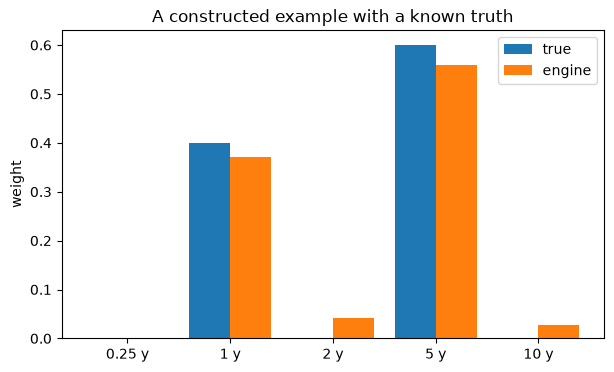

In [6]:
# A constructed example with a known truth (seeded): the engine recovers the tranche weights approximately
rng = np.random.default_rng(42)
n_q = 60
level, slope = np.zeros(n_q), np.zeros(n_q)
level[0], slope[0] = 0.03, 0.01
for t in range(1, n_q):
    level[t] = 0.03 + 0.9 * (level[t - 1] - 0.03) + rng.normal(0, 0.002)
    slope[t] = 0.01 + 0.8 * (slope[t - 1] - 0.01) + rng.normal(0, 0.002)
grid_years = np.array([0.25, 1.0, 2.0, 5.0, 10.0])
shape = 1 - np.exp(-grid_years[None, :] / 2)
tranche_yields = level[:, None] + slope[:, None] * shape + rng.normal(0, 0.0003, (n_q, 5))
client_rate = 0.4 * tranche_yields[:, 1] + 0.6 * tranche_yields[:, 3] - 0.01 + rng.normal(0, 0.0002, n_q)
portfolio = behavioural.replicating_portfolio(client_rate, tranche_yields, grid_years)
true_weights = np.array([0.0, 0.4, 0.0, 0.6, 0.0])
print("engine weights:", np.round(portfolio.weights, 3), "| sum", round(float(portfolio.weights.sum()), 6))
wam_engine = behavioural.weighted_average_maturity(grid_years, portfolio.weights)
wam_true = behavioural.weighted_average_maturity(grid_years, true_weights)
print(f"average maturity: engine {wam_engine:.4f} | true {wam_true:.4f}")
print(f"margin volatility {portfolio.margin_volatility:.5f}")
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(np.arange(5) - 0.2, true_weights, 0.4, label="true")
ax.bar(np.arange(5) + 0.2, portfolio.weights, 0.4, label="engine")
ax.set_xticks(np.arange(5), [f"{y:g} y" for y in grid_years])
ax.set_ylabel("weight")
ax.set_title("A constructed example with a known truth")
ax.legend()
plt.show()

The engine finds the two true tranches, the 1-year and the 5-year, with weights close to 0.4 and 0.6, but it leaves small weights on their neighbours, the 2-year and the 10-year tranches. That is the instability in a small space: tranche yields move together, so a portfolio with a little of a neighbour is almost as good at replicating the client rate as the true one, and the optimiser has no strong reason to prefer either. The average maturity moves less than the weights, 1.76 years against a true 1.70, which is why practitioners quote the maturity and not the weights. The example is constructed and seeded, it is not data of the bank, and it shows one draw, not the spread of the estimates.

### Step 3: the deposit beta

The rate a bank pays on a deposit does not follow the market rate one to one. The **deposit beta** is the pass-through, and it is asymmetric: a bank passes rises on slowly and cuts quickly. With the client rate $i$, a market change $\Delta r$ and the betas up and down:

$$i_{new} = i + \beta\, \Delta r, \qquad \beta = \beta_{up}\ \text{if}\ \Delta r \ge 0,\ \beta_{down}\ \text{otherwise}$$

(Drechsler, Savov and Schnabl, 2021, https://doi.org/10.1111/jofi.13013; dossier 05, D.3). A low beta means the deposits behave like long-duration fixed-rate liabilities, which is why it matters. The engine's `deposit_beta_passthrough` does not floor the result; the caller floors. The committed model fits both betas at each date by least squares through the origin on the last 16 quarters of the cost of deposits against the 3-month Treasury yield. The next cell prints the fitted betas at the three dates and applies them to a client rate of 1 percent for a +100 and a -100 bp market move.

2021-12-31 beta up 0.0236 beta down 0.0315
    client rate after +100 bp 0.01024 | after -100 bp 0.00969
2022-06-30 beta up 0.0748 beta down 0.0315
    client rate after +100 bp 0.01075 | after -100 bp 0.00969
2022-12-31 beta up 0.2611 beta down 0.0315
    client rate after +100 bp 0.01261 | after -100 bp 0.00969
beta used by the dynamic NII at 2022-Q2 (the up value): 0.0748


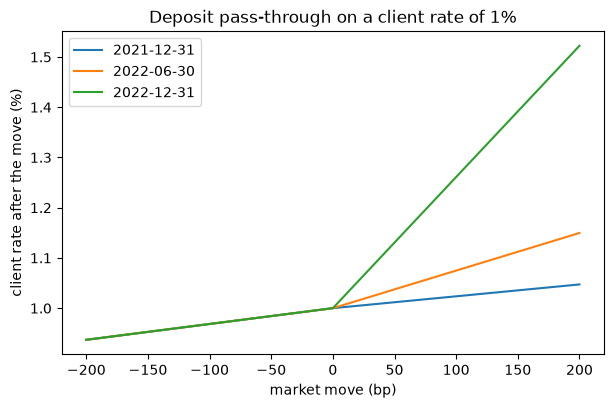

In [7]:
# The fitted betas at the three dates and the pass-through of market moves on a client rate of 1 percent
moves = np.linspace(-0.02, 0.02, 41)
fig, ax = plt.subplots(figsize=(7, 4.2))
for m in fit["nmd_models"]:
    b = m["deposit_beta"]
    client = [behavioural.deposit_beta_passthrough(0.01, dr, b["up"], b["down"]) for dr in moves]
    ax.plot(moves * 1e4, np.array(client) * 100, label=m["valuation_date"])
    up = behavioural.deposit_beta_passthrough(0.01, 0.01, b["up"], b["down"])
    down = behavioural.deposit_beta_passthrough(0.01, -0.01, b["up"], b["down"])
    print(f"{m['valuation_date']} beta up {b['up']:.4f} beta down {b['down']:.4f}")
    print(f"    client rate after +100 bp {up:.5f} | after -100 bp {down:.5f}")
beta_nii = out["assumptions"]["deposit_beta"]["value"]
print("beta used by the dynamic NII at 2022-Q2 (the up value):", round(beta_nii, 4))
ax.set_xlabel("market move (bp)")
ax.set_ylabel("client rate after the move (%)")
ax.set_title("Deposit pass-through on a client rate of 1%")
ax.legend()
plt.show()

Each line is a client rate of 1 percent after a market move, and its slope is the beta: the right half, a rise, is slightly flatter than the left half, a cut, at 2021-Q4, and the slope of the right half steepens until at 2022-Q4 it is eight times the slope of the left half, because the fitted beta up goes from 0.0236 to 0.2611 while the beta down stays at 0.0315. A bank with the earliest beta passes about 2.4 bp of a +100 bp move to its depositors, so its deposits look like fixed-rate liabilities and its EVE under a rise looks better than it is if the true beta turns out higher. The picture shows the fitted betas and says nothing about whether the 2023 depositors would have accepted them, which is the question the liquidity topic takes up.

### Step 4: prepayment and early redemption

Mortgages and term deposits can be repaid early, which shortens their cash flows. Two conventions measure the speed. The **single monthly mortality** (SMM) is the fraction of the balance prepaid in a month, and the **conditional prepayment rate** (CPR) is the same speed at an annual rate:

$$SMM = 1 - (1 - CPR)^{1/12}, \qquad CPR = 1 - (1 - SMM)^{12}$$

(Fuster, Lucca and Vickery, 2022, FRBNY Staff Report 1001, https://www.newyorkfed.org/medialibrary/media/research/staff_reports/sr1001.pdf; dossier 05, D.4). The **PSA benchmark** is a standard ramp: at 100 percent PSA the CPR is 0.2 percent in month 1 and rises 0.2 percent a month to 6 percent at month 30, flat after; $x$ percent PSA scales it, $CPR_m = \frac{x}{100}\min(0.002\, m,\ 0.06)$ (the primary text of SIFMA was not retrieved; the engine marks the formula UNVERIFIED against it). The standardised framework scales the base rates by shock with the multipliers of SRP31.119 (Table 5) and SRP31.125 (Table 6):

$$CPR_i = \min(1,\ \gamma_i\, CPR^0), \qquad TDRR_i = \min(1,\ u_i\, TDRR^0)$$

The next cell converts the 8 percent CPR assumption of the bank, prints the PSA ramp at some months for 100 and 150 percent, and prints the multipliers and the rates by shock.

CPR 0.0800 -> SMM 0.006924 -> CPR 0.0800
PSA 100 and 150 at months 1, 10, 30 and 60: [0.002 0.02  0.06  0.06 ] [0.003 0.03  0.09  0.09 ]
parallel up            CPR  0.0640  TDRR  0.0600
parallel down          CPR  0.0960  TDRR  0.0400
steepener              CPR  0.0640  TDRR  0.0400
flattener              CPR  0.0960  TDRR  0.0600
short up               CPR  0.0640  TDRR  0.0600
short down             CPR  0.0960  TDRR  0.0400


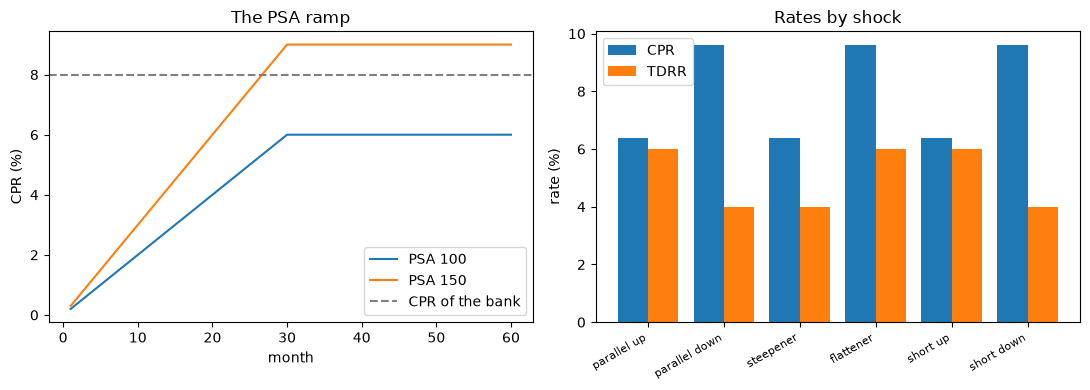

In [8]:
# Convert CPR and SMM, read the PSA ramp, and scale the base rates by shock with the multipliers of the standard
cpr0 = out["assumptions"]["prepayment_cpr"]["value"]
tdrr0 = out["assumptions"]["term_deposit_redemption_rate"]["value"]
smm = slotting.smm_from_cpr(cpr0)
print(f"CPR {cpr0:.4f} -> SMM {smm:.6f} -> CPR {slotting.cpr_from_smm(smm):.4f}")
months = np.arange(1, 61)
psa100, psa150 = slotting.psa_cpr(months, 100.0), slotting.psa_cpr(months, 150.0)
print("PSA 100 and 150 at months 1, 10, 30 and 60:", psa100[[0, 9, 29, 59]], psa150[[0, 9, 29, 59]])
cpr_s = [slotting.prepayment_cpr(s, cpr0) for s in shocks.SHOCKS]
tdrr_s = [slotting.term_deposit_redemption_rate(s, tdrr0) for s in shocks.SHOCKS]
for s, c, t in zip(shocks.SHOCKS, cpr_s, tdrr_s):
    print(f"{NAME[s]:22s} CPR {c:7.4f}  TDRR {t:7.4f}")
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
left.plot(months, psa100 * 100, label="PSA 100")
left.plot(months, psa150 * 100, label="PSA 150")
left.axhline(cpr0 * 100, color="grey", linestyle="--", label="CPR of the bank")
left.set_xlabel("month")
left.set_ylabel("CPR (%)")
left.set_title("The PSA ramp")
left.legend()
x = np.arange(6)
right.bar(x - 0.2, np.array(cpr_s) * 100, 0.4, label="CPR")
right.bar(x + 0.2, np.array(tdrr_s) * 100, 0.4, label="TDRR")
right.set_xticks(x, [NAME[s] for s in shocks.SHOCKS], rotation=30, ha="right", fontsize=8)
right.set_ylabel("rate (%)")
right.set_title("Rates by shock")
right.legend()
fig.tight_layout()
plt.show()

On the left the PSA ramp climbs month by month to its ceiling at month 30, 6 percent at 100 PSA and 9 percent at 150, and the flat dashed line of the bank's 8 percent sits between the two ceilings, so the bank assumes prepayment faster than the standard ramp but slower than 150 percent of it. On the right the multipliers of the standard bend the base rates by shock: the parallel-up, steepener and short-up shocks lower the prepayment rate to 6.4 percent, and the other three raise it to 9.6 percent, while the early redemption of term deposits is 6 percent under the parallel-up, short-up and flattener shocks and 4 percent under the rest. The picture shows assumptions, not behaviour: the call report has no loan history to test them against.

When the bank has loan-level history, the practitioner model is a **logit of the SMM** on the refinancing incentive (the contract rate minus the market rate) and the seasoning (the age of the loan in months): $SMM = 1 / (1 + e^{-(b_0 + b_1\, incentive + b_2\, seasoning)})$ (dossier 05, D.4). The engine's `fit_prepayment_logit` fits it by maximum likelihood with Newton's method and says plainly when it does not converge (no exception: the bake then uses the PSA benchmark). The call report holds no loan history, so the bank of this case does not fit one; the next cell fits a **constructed example with a known truth**, seeded, to show the function, the standard errors and the recovery of the coefficients.

loans: 5000 | prepaid share: 0.0358
converged: yes
b0: true   -5.000 | estimate   -4.856 | standard error   0.226
    within 2 standard errors yes
b1: true   60.000 | estimate   56.801 | standard error   7.385
    within 2 standard errors yes
b2: true    0.030 | estimate    0.024 | standard error   0.005
    within 2 standard errors yes


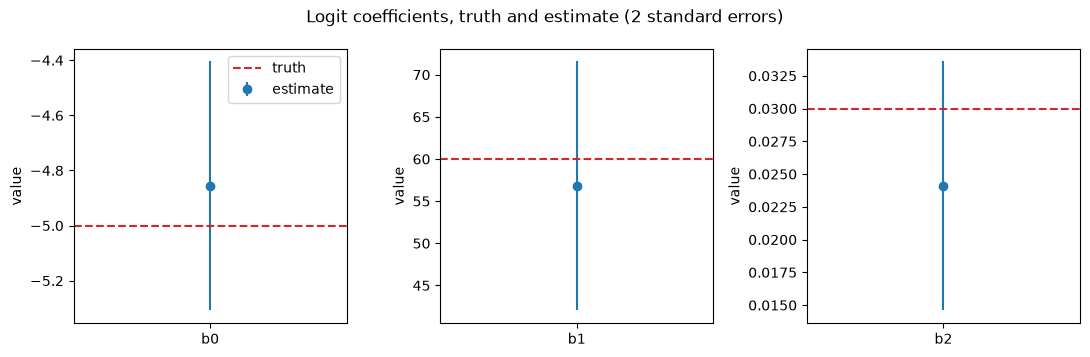

In [9]:
# Fit the prepayment logit on a constructed, seeded example with known coefficients and read the recovery
rng = np.random.default_rng(42)
n_loans = 5000
incentive = rng.uniform(-0.01, 0.03, n_loans)
seasoning = rng.uniform(1, 60, n_loans)
true_coef = np.array([-5.0, 60.0, 0.03])
score = true_coef[0] + true_coef[1] * incentive + true_coef[2] * seasoning
prepaid = (rng.uniform(size=n_loans) < 1.0 / (1.0 + np.exp(-score))).astype(int)
logit = behavioural.fit_prepayment_logit(incentive, seasoning, prepaid)
print("loans:", logit.n, "| prepaid share:", round(float(prepaid.mean()), 4))
print("converged:", NAME[logit.converged])
for name, truth, est, err in zip(("b0", "b1", "b2"), true_coef, logit.coef, logit.std_err):
    inside = NAME[bool(abs(est - truth) < 2 * err)]
    print(f"{name}: true {truth:8.3f} | estimate {est:8.3f} | standard error {err:7.3f}")
    print(f"    within 2 standard errors {inside}")
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
for ax, name, truth, est, err in zip(axes, ("b0", "b1", "b2"), true_coef, logit.coef, logit.std_err):
    ax.errorbar([0], [est], yerr=[2 * err], fmt="o", label="estimate")
    ax.axhline(truth, color="tab:red", linestyle="--", label="truth")
    ax.set_xticks([0], [name])
    ax.set_ylabel("value")
axes[0].legend()
fig.suptitle("Logit coefficients, truth and estimate (2 standard errors)")
fig.tight_layout()
plt.show()

Each panel shows one coefficient: the dot is the estimate, the bar is two standard errors either side, and the red line is the truth used to generate the data. All three red lines fall inside their bars, so the logit recovers the coefficients within sampling error, with 5,000 loans and a prepaid share near 3.6 percent. The slope on the seasoning, b2, has the widest bar relative to its size, and the intercept the narrowest. This is a constructed example: it shows that the function works and what its standard errors look like, and it says nothing about the bank, whose call report holds no loan-level history, so the bake of the bank uses the PSA benchmark instead.

### Step 5: the EVE with and without the behavioural layer

The six shocks of notebook 02 move the EVE. The **EVE risk measure** is the worst of the six: for each shock the sum of the currencies with a loss, then the maximum over shocks (SRP31.129); with one currency it is the largest positive delta EVE, or zero if none is positive. The **supervisory outlier test** compares it with 15 percent of Tier 1 capital (SRP31.82 to SRP31.83; dossier 01, H.5) and is breached only when the ratio is strictly above. The pipeline computed the delta EVE of each shock twice, with the capped behavioural flows of Step 1 and with every non-maturity deposit overnight (contractual), and committed both. The next cell takes the six committed values of each treatment under the 2024 calibration, computes the measure with `eve_risk_measure` (a matrix of six shocks by one currency) and the test with `outlier_test`, and draws the six delta EVE of each treatment.

parallel up                   3,389,351       12,611,380
parallel down                -4,783,706      -15,915,274
steepener                     3,418,185        8,589,837
flattener                    -2,993,642       -5,921,844
short up                         43,834        3,316,400
short down                       89,516       -3,343,657
behavioural: measure 3,418,185 | Tier 1 16,349,000
    ratio 0.2091 | threshold 0.15 | breached yes
contractual: measure 12,611,380 | Tier 1 16,349,000
    ratio 0.7714 | threshold 0.15 | breached yes


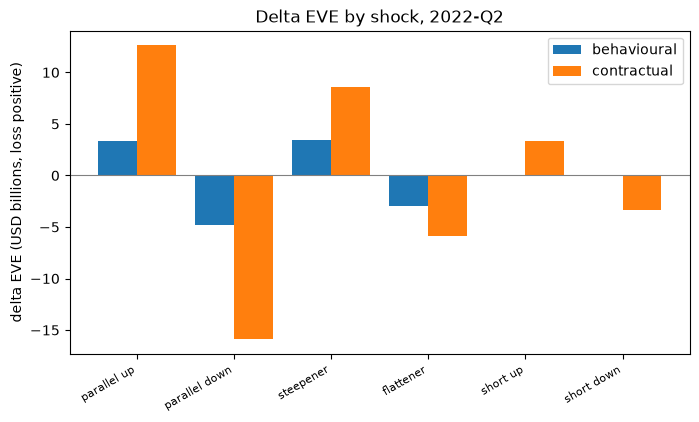

In [10]:
# The six delta EVE of each treatment at 2022-Q2, the EVE risk measure and the outlier test
rows = {s["shock"]: s for s in out["behavioural_comparison"] if s["calibration"] == "2024"}
tier1 = out["scenarios"][0]["outlier"]["tier1"]
measure, test = {}, {}
for s in shocks.SHOCKS:
    print(f"{NAME[s]:22s} {rows[s]['delta_eve_behavioural']:16,.0f} {rows[s]['delta_eve_contractual']:16,.0f}")
for treatment in ("behavioural", "contractual"):
    deltas = np.array([rows[s][f"delta_eve_{treatment}"] for s in shocks.SHOCKS]).reshape(6, 1)
    measure[treatment] = eve_nii.eve_risk_measure(deltas)
    test[treatment] = eve_nii.outlier_test(measure[treatment], tier1)
    t = test[treatment]
    print(f"{NAME[treatment]}: measure {measure[treatment]:,.0f} | Tier 1 {tier1:,.0f}")
    print(f"    ratio {t.ratio:.4f} | threshold {t.threshold:.2f} | breached {NAME[t.breached]}")
x = np.arange(6)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(x - 0.2, [rows[s]["delta_eve_behavioural"] / 1e6 for s in shocks.SHOCKS], 0.4, label=NAME["behavioural"])
ax.bar(x + 0.2, [rows[s]["delta_eve_contractual"] / 1e6 for s in shocks.SHOCKS], 0.4, label=NAME["contractual"])
ax.axhline(0, color="grey", linewidth=0.8)
ax.set_xticks(x, [NAME[s] for s in shocks.SHOCKS], rotation=30, ha="right", fontsize=8)
ax.set_ylabel("delta EVE (USD billions, loss positive)")
ax.set_title("Delta EVE by shock, 2022-Q2")
ax.legend()
plt.show()

The contractual bars are taller than the behavioural ones under every shock that loses, by a factor of about four for the parallel-up shock, and the worst shock changes with the treatment: the steepener under the behavioural reading, the parallel-up shock under the contractual one. The EVE risk measure is the tallest positive bar of each treatment, which is why its ratio to Tier 1 is the figure printed above. The picture shows the delta EVE the product committed and the engine only aggregates them, so it says what the behavioural layer does to the measure and not whether the layer is right.

The engine ties the two measures into one test, `irrbb.eve_with_without_behavioural`, because the SVB review taught that the behavioural assumption is the lever that moves the measure most (dossier 05, D.7). The test's statistic is the difference between the contractual and the behavioural measure as a share of Tier 1, and its light is green when the absolute statistic is at most 0.05, amber at most 0.15 and red above (Contraste internal gates, not regulatory thresholds); and it is red whatever the size when the behavioural measure passes the outlier test and the contractual one breaches it, which means the assumptions **hide a breach**. The next cell runs it at the three valuation dates, measuring each treatment with the engine, and draws the outlier ratios against the 15 percent line.

2021-Q4: statistic (difference over Tier 1) 0.7222
    difference in money 10,560,453 | hidden breach: no
    ratio 0.3406 / 1.0629
2022-Q2: statistic (difference over Tier 1) 0.5623
    difference in money 9,193,196 | hidden breach: no
    ratio 0.2091 / 0.7714
2022-Q4: statistic (difference over Tier 1) 0.4655
    difference in money 7,911,085 | hidden breach: no
    ratio 0.1808 / 0.6463


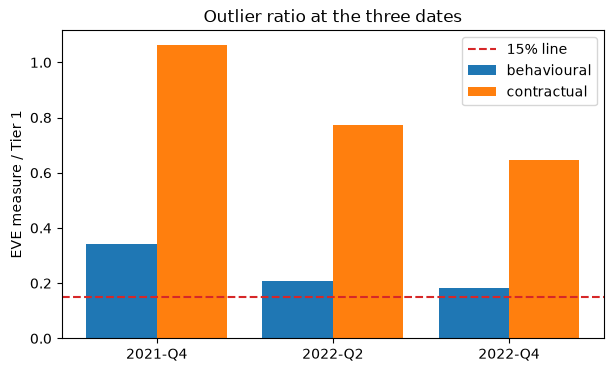

In [11]:
# The measure, the outlier ratio and the with-and-without test at the three valuation dates
ratios = {"behavioural": [], "contractual": []}
for q, d in docs.items():
    rows_q = {s["shock"]: s for s in d["outputs"]["behavioural_comparison"] if s["calibration"] == "2024"}
    tier1_q = d["outputs"]["scenarios"][0]["outlier"]["tier1"]
    measures = {}
    for treatment in ratios:
        deltas = np.array([rows_q[s][f"delta_eve_{treatment}"] for s in shocks.SHOCKS]).reshape(6, 1)
        measures[treatment] = eve_nii.eve_risk_measure(deltas)
        ratios[treatment].append(eve_nii.outlier_test(measures[treatment], tier1_q).ratio)
    result = rv_irrbb.eve_with_without_behavioural(measures["behavioural"], measures["contractual"], tier1_q)
    hidden_flag = NAME[result.extras["hidden_breach"]]
    print(f"{q}: statistic (difference over Tier 1) {result.statistic:.4f}")
    print(f"    difference in money {result.metric:,.0f} | hidden breach: {hidden_flag}")
    print(f"    ratio {ratios['behavioural'][-1]:.4f} / {ratios['contractual'][-1]:.4f}")
x = np.arange(3)
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(x - 0.2, ratios["behavioural"], 0.4, label=NAME["behavioural"])
ax.bar(x + 0.2, ratios["contractual"], 0.4, label=NAME["contractual"])
ax.axhline(0.15, color="tab:red", linestyle="--", label="15% line")
ax.set_xticks(x, list(docs))
ax.set_ylabel("EVE measure / Tier 1")
ax.set_title("Outlier ratio at the three dates")
ax.legend()
plt.show()

Both treatments sit above the dashed 15 percent line at every date, so the behavioural layer does not move the measure across the outlier line here: it only brings the ratio down, from 0.34 at 2021-Q4 to 0.21 and 0.18, while the contractual ratio falls from 1.06 to 0.65. The statistic of the with-and-without test, the difference between the two measures over Tier 1, is large at every date, and the test is red because of that size and not because of a hidden breach. The picture shows three dates of one bank; it cannot say whether the downward trend is deleveraging or the effect of a changing assumption, and the validation test of notebook 05 asks that question.

What would a **hidden breach** look like? The three dates above breach the outlier test under both treatments, so the engine's red light comes from the size of the difference, not from a hidden breach. The next cell calls the same engine function on **constructed numbers** (not the bank's) to show the other red: a behavioural measure at 14 percent of Tier 1, under the 15 percent line, against a contractual one at 40 percent. The behavioural assumption makes the bank pass a test it would fail with the contractual reading. This is the pattern the Federal Reserve's review describes in the failed bank, shown here as a call to the function, not as a finding about any bank.

In [12]:
# Constructed numbers: the behavioural measure passes the 15 percent line and the contractual one breaches it
hidden = rv_irrbb.eve_with_without_behavioural(0.14 * 1000.0, 0.40 * 1000.0, 1000.0)
print("light:", hidden.light.value, "| statistic:", round(hidden.statistic, 4))
print("hidden breach:", NAME[hidden.extras["hidden_breach"]])

light: red | statistic: 0.26
hidden breach: yes


## Results

**Answer:** the assumption about the deposits moves the EVE measure by a multiple but not across the line. At 2022-Q2 the risk measure is 3,418,185 with the capped behavioural flows and 12,611,380 with every deposit overnight, 3.7 times as much; as a share of Tier 1 of 16,349,000 that is 0.2091 and 0.7714 against a line of 0.15, so both readings breach. The with-and-without test has a statistic of 0.5623, red because of the size of the difference and not because of a hidden breach.

- **The caps.** All three requests exceed their caps, so all three are cut: 95 to 90 percent and 6 to 5 years for the retail transactional deposits, 75 to 70 percent and 5 to 4.5 years for the retail non-transactional ones, 60 to 50 percent and 5 to 4 years for the wholesale ones. The request as stated would lower the present value of the wholesale liability by 5,035,629 and raise the EVE by that much, about a third of the bank's Tier 1: the caps keep the assumption from making the bank look safer than the standard allows.
- **The replicating portfolio.** The wholesale fits give an average maturity of 4.7595, 4.2049 and 5.0000 years at the three dates, and the last has reached the ceiling of its own design, above the 4 years the standard allows. In the constructed example the engine finds 0.371 and 0.560 on the 1-year and 5-year tranches against a truth of 0.4 and 0.6, so the weights are an estimate with a flat objective, not a measurement; a validator should ask how they move when the window moves (notebook 05).
- **The beta.** The fitted beta up rises from 0.0236 to 0.0748 and to 0.2611 across the three dates, while the beta down stays at 0.0315, consistent with the hiking quarters entering the estimation windows. A bank with a beta of 0.0236 passes 2.4 bp of a +100 bp move to its depositors.
- **Prepayment.** The 8 percent CPR is a monthly SMM of 0.006924, and the round trip returns 0.0800. At 100 percent PSA the CPR reaches 0.06 at month 30, at 150 percent PSA 0.09, so the bank's assumption sits between the two ceilings. The multipliers lower the prepayment rate to 0.0640 under the parallel-up, steepener and short-up shocks and raise it to 0.0960 under the other three. In the constructed example the logit recovers the three coefficients within two standard errors.
- **Across the dates.** The behavioural ratio falls from 0.3406 to 0.2091 and to 0.1808 across the three dates, towards the line; the contractual one from 1.0629 to 0.7714 and to 0.6463. The last constructed call shows the other red: a behavioural measure of 14 percent of Tier 1 passes the test, a contractual one of 40 percent breaches it, and the engine flags it with a statistic of 0.26.
- **What the notebook does not show.** The stability of the weights across estimation windows and the test that flags a behavioural change at a breach (notebook 05), the dynamic effect of the beta on net interest income (notebook 04), and any estimate of prepayment on real loans: the call report has none.

## Summary

- A non-maturity deposit is a non-core part overnight and a core part in the two bands that bracket its core maturity; the standard caps the core share and maturity by category, and the engine reports the request, the cap and the value used.
- The replicating portfolio chooses tranche weights that minimise the variance of the margin; the weights are not stable because tranche yields move together, and the implied maturity is the half of the weighted tranche maturity.
- The deposit beta is asymmetric and low, which makes deposits behave like long fixed-rate liabilities; prepayment and early redemption are converted with SMM, CPR, PSA and the multipliers by shock.
- The EVE risk measure is the worst of the six shocks; the behavioural layer moves it by a multiple, and the engine tests the two readings together and flags a breach the behavioural reading hides.
- The two constructed examples have a known truth and are not data of the bank.

**What to try next.** Change the core share request of `nmd_split` below its cap and watch the flag `cap_applied` and the EVE. Then continue with notebook 04, the dynamic NII and the distributions.

## References

- BCBS, Standards: Interest rate risk in the banking book, SRP31.82 to SRP31.83 (the outlier test), SRP31.107 to SRP31.112 (non-maturity deposits, Table 4), SRP31.119 and SRP31.125 (Tables 5 and 6) and SRP31.129 (the EVE risk measure). https://www.bis.org/basel_framework/chapter/SRP/31.htm
- BCBS (2016), d368, Standards: Interest rate risk in the banking book, footnote 38 (the replicating portfolio). https://www.bis.org/bcbs/publ/d368.htm
- Kalkbrener, M. and Willing, J. (2004), Risk management of non-maturing liabilities, Journal of Banking and Finance 28(7). https://doi.org/10.1016/S0378-4266(03)00131-6
- Drechsler, I., Savov, A. and Schnabl, P. (2021), Banking on deposits: maturity transformation without interest rate risk, Journal of Finance 76(3). https://doi.org/10.1111/jofi.13013
- Fuster, A., Lucca, D. and Vickery, J. (2022), Mortgage-backed securities, FRBNY Staff Report 1001. https://www.newyorkfed.org/medialibrary/media/research/staff_reports/sr1001.pdf
- FDIC, BankFind financials, public domain. https://api.fdic.gov/banks/financials
- US Department of the Treasury, Daily Treasury Par Yield Curve Rates, public domain. https://home.treasury.gov/resource-center/data-chart-center/interest-rates
- Dossier 05 of the Contraste research, sections D.3, D.4 and D.7; dossier 01, section H.5.